In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

오늘 베운 내용 복습 위주

데이터 : 수업용 데이터(22_열처리.csv)

In [ ]:
Path='C:\\ex\\data\\22_열처리 copy 4.csv'
df=pd.read_csv(Path)

In [ ]:
# 각 컬럼의 자료형 및 결측치 확인
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 188 entries, 0 to 187
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   timestamp  188 non-null    str    
 1   설비         188 non-null    int64  
 2   제어출력       188 non-null    float64
 3   소입로온도      188 non-null    float64
dtypes: float64(2), int64(1), str(1)
memory usage: 9.5 KB


In [ ]:
# timestamp의 자료형을 str에서 datetime 타입으로 변환
df['timestamp'] = pd.to_datetime(df['timestamp'])

# 인덱스 설정(set_index) 및 시간순 정렬(sort_index)
df = df.set_index('timestamp').sort_index()

In [ ]:
# 두 센서를 1분 구간으로 묶었을 때, 구간에 속하는 값들의 평균으로 데이터프레임화
a_min=df[['제어출력','소입로온도']].resample('1min').mean()

# 1분 구간 설정 시, 각 컬럼의 빈칸 확인
print('구간 1분 설정 시, 제어출력 빈칸 :', a_min['제어출력'].isna().sum())
print('구간 1분 설정 시, 소입로온도 빈칸 :', a_min['소입로온도'].isna().sum())

구간 1분 설정 시, 제어출력 빈칸 : 1
구간 1분 설정 시, 소입로온도 빈칸 : 1


In [ ]:
# 1분 구간 설정 시의 빈칸 파악
a_min['제어출력'].isna()  # 2024-03-01 09:10:00에 빈칸 있음

timestamp
2024-03-01 09:00:00    False
2024-03-01 09:01:00    False
2024-03-01 09:02:00    False
2024-03-01 09:03:00    False
2024-03-01 09:04:00    False
2024-03-01 09:05:00    False
2024-03-01 09:06:00    False
2024-03-01 09:07:00    False
2024-03-01 09:08:00    False
2024-03-01 09:09:00    False
2024-03-01 09:10:00     True
2024-03-01 09:11:00    False
2024-03-01 09:12:00    False
2024-03-01 09:13:00    False
2024-03-01 09:14:00    False
2024-03-01 09:15:00    False
2024-03-01 09:16:00    False
2024-03-01 09:17:00    False
2024-03-01 09:18:00    False
2024-03-01 09:19:00    False
2024-03-01 09:20:00    False
2024-03-01 09:21:00    False
2024-03-01 09:22:00    False
2024-03-01 09:23:00    False
2024-03-01 09:24:00    False
2024-03-01 09:25:00    False
2024-03-01 09:26:00    False
2024-03-01 09:27:00    False
2024-03-01 09:28:00    False
2024-03-01 09:29:00    False
2024-03-01 09:30:00    False
2024-03-01 09:31:00    False
2024-03-01 09:32:00    False
2024-03-01 09:33:00    False
Freq

In [ ]:
# 빈칸이 있는 인덱스 뽑아내기
a_min.index[a_min['제어출력'].isna()]

DatetimeIndex(['2024-03-01 09:10:00'], dtype='datetime64[us]', name='timestamp', freq='min')

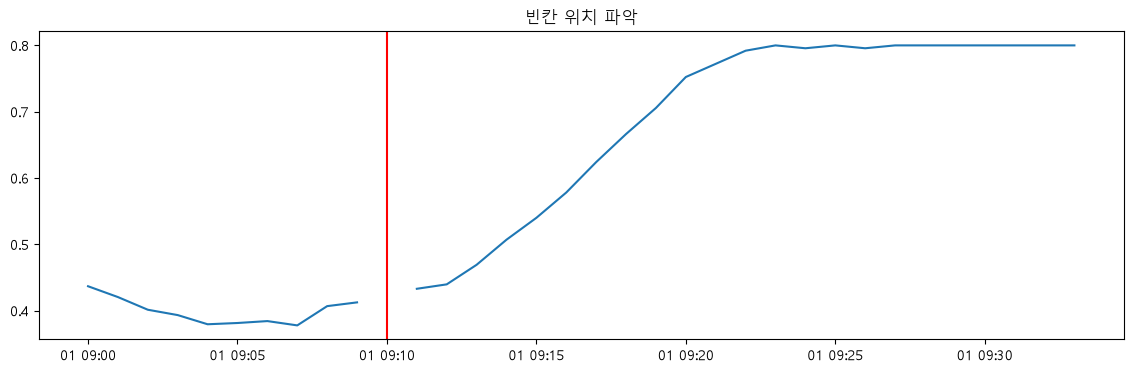

In [22]:
# 결측의 위치를 알기 위해 이를 시각화
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Malgun Gothic'

# 결측이 있는 index를 nan_time에 할당
nan_time = a_min.index[a_min['제어출력'].isna()]

plt.figure(figsize=(14, 4))
plt.plot(a_min['제어출력'])

# 빈칸이 있는 시간 인덱스를 수직선으로 표시
plt.axvline(nan_time, color='red')

plt.title('빈칸 위치 파악')
plt.show()

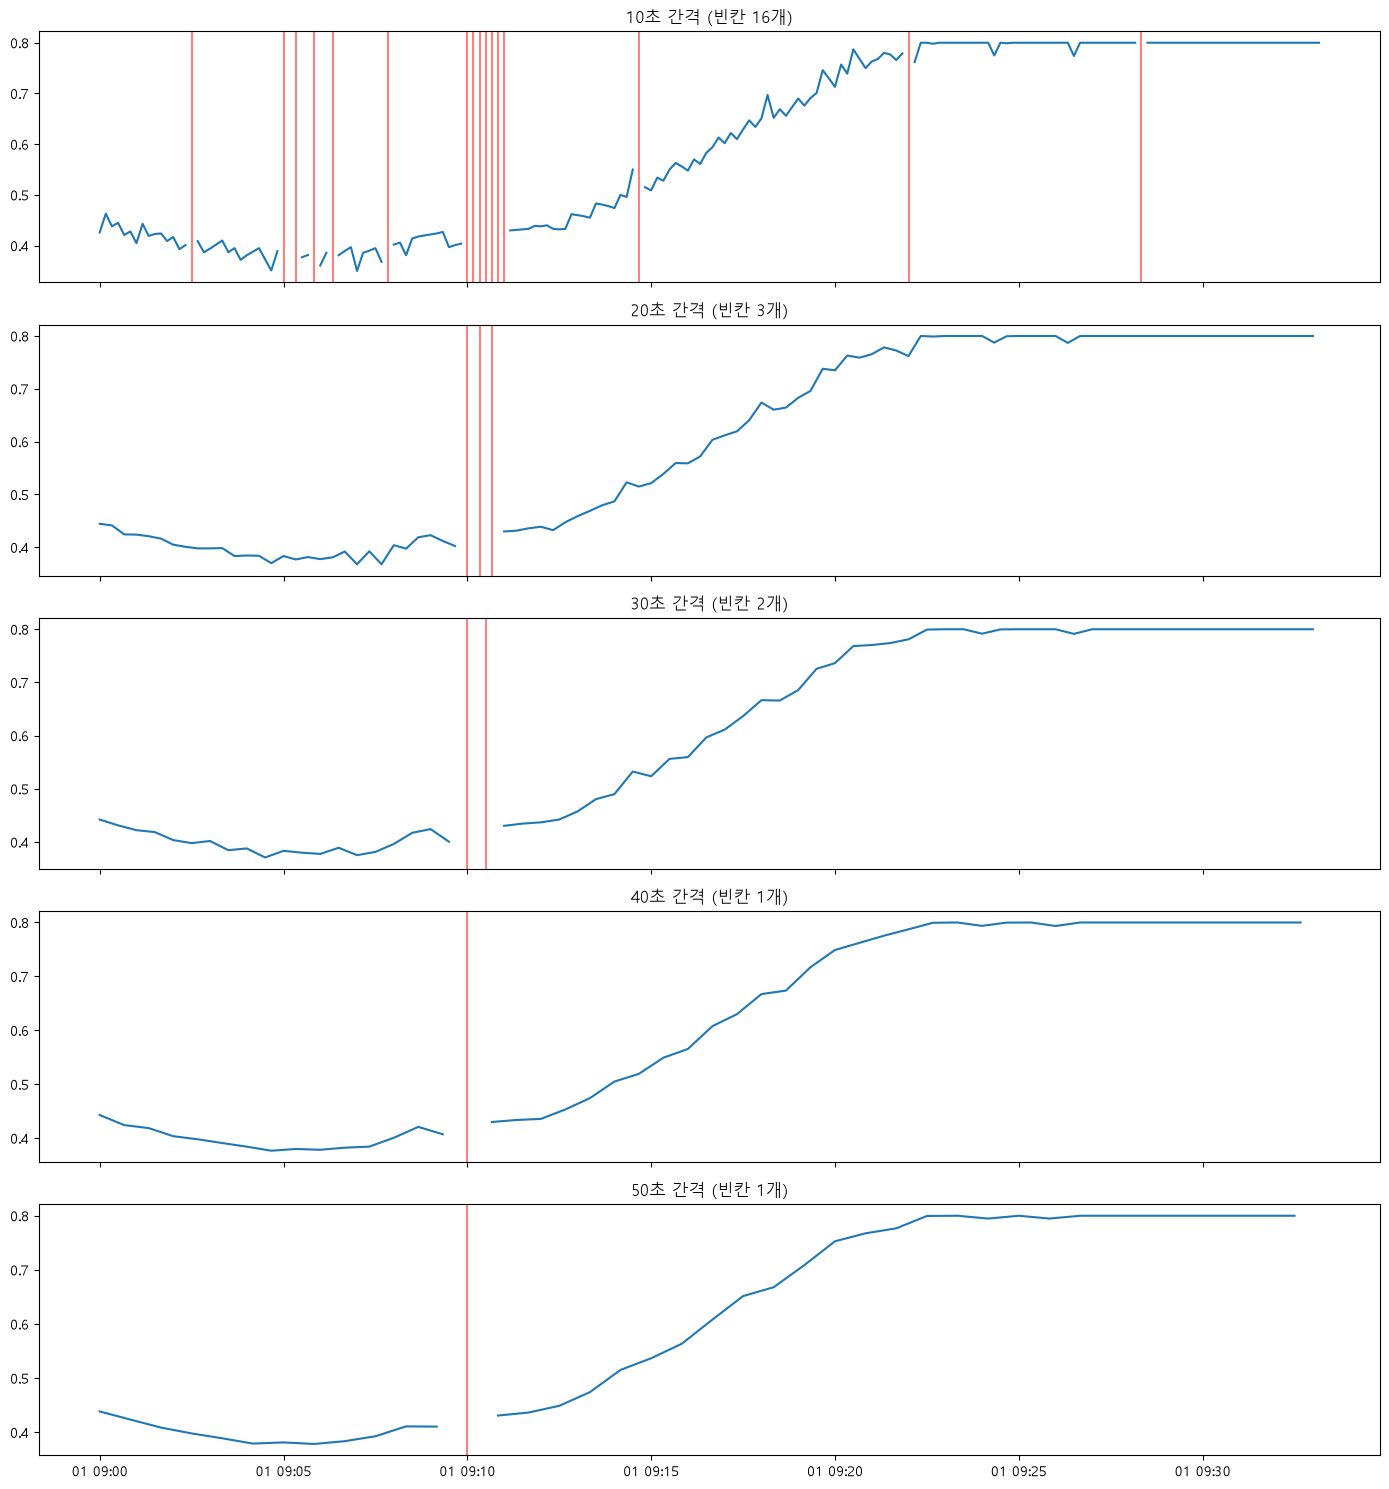

In [30]:
# 리샘플링 구간을 10초에서 50초까지 설정
sec = [10, 20, 30, 40, 50]

# 가로행을 sec의 요소수 만큼 배정
# x축 공유하도록 설정 : sharex=True
fig, axes = plt.subplots(len(sec), 1, figsize=(14, 15), sharex=True)

# ax와 sec를 zip으로 언패킹
for ax, second in zip(axes, sec):
    a = df[['제어출력','소입로온도']].resample(f'{second}s').mean() # 10,20,30,40,50초 구간을 각 구간에 속하는 값들의 평균으로 리샘플링
    nan_time = a.index[a['제어출력'].isna()] # 각 구간에 대해 빈칸이 있는 인덱스들을 뽑아서 nan_time에 저장

    ax.plot(a['제어출력'])
    for t in nan_time:
        ax.axvline(t, color='red', alpha=0.5) # 빈칸의 위치를 수직선으로 반복 표시
        ax.set_title(f'{second}초 간격 (빈칸 {len(nan_time)}개)')

plt.tight_layout()
plt.show()

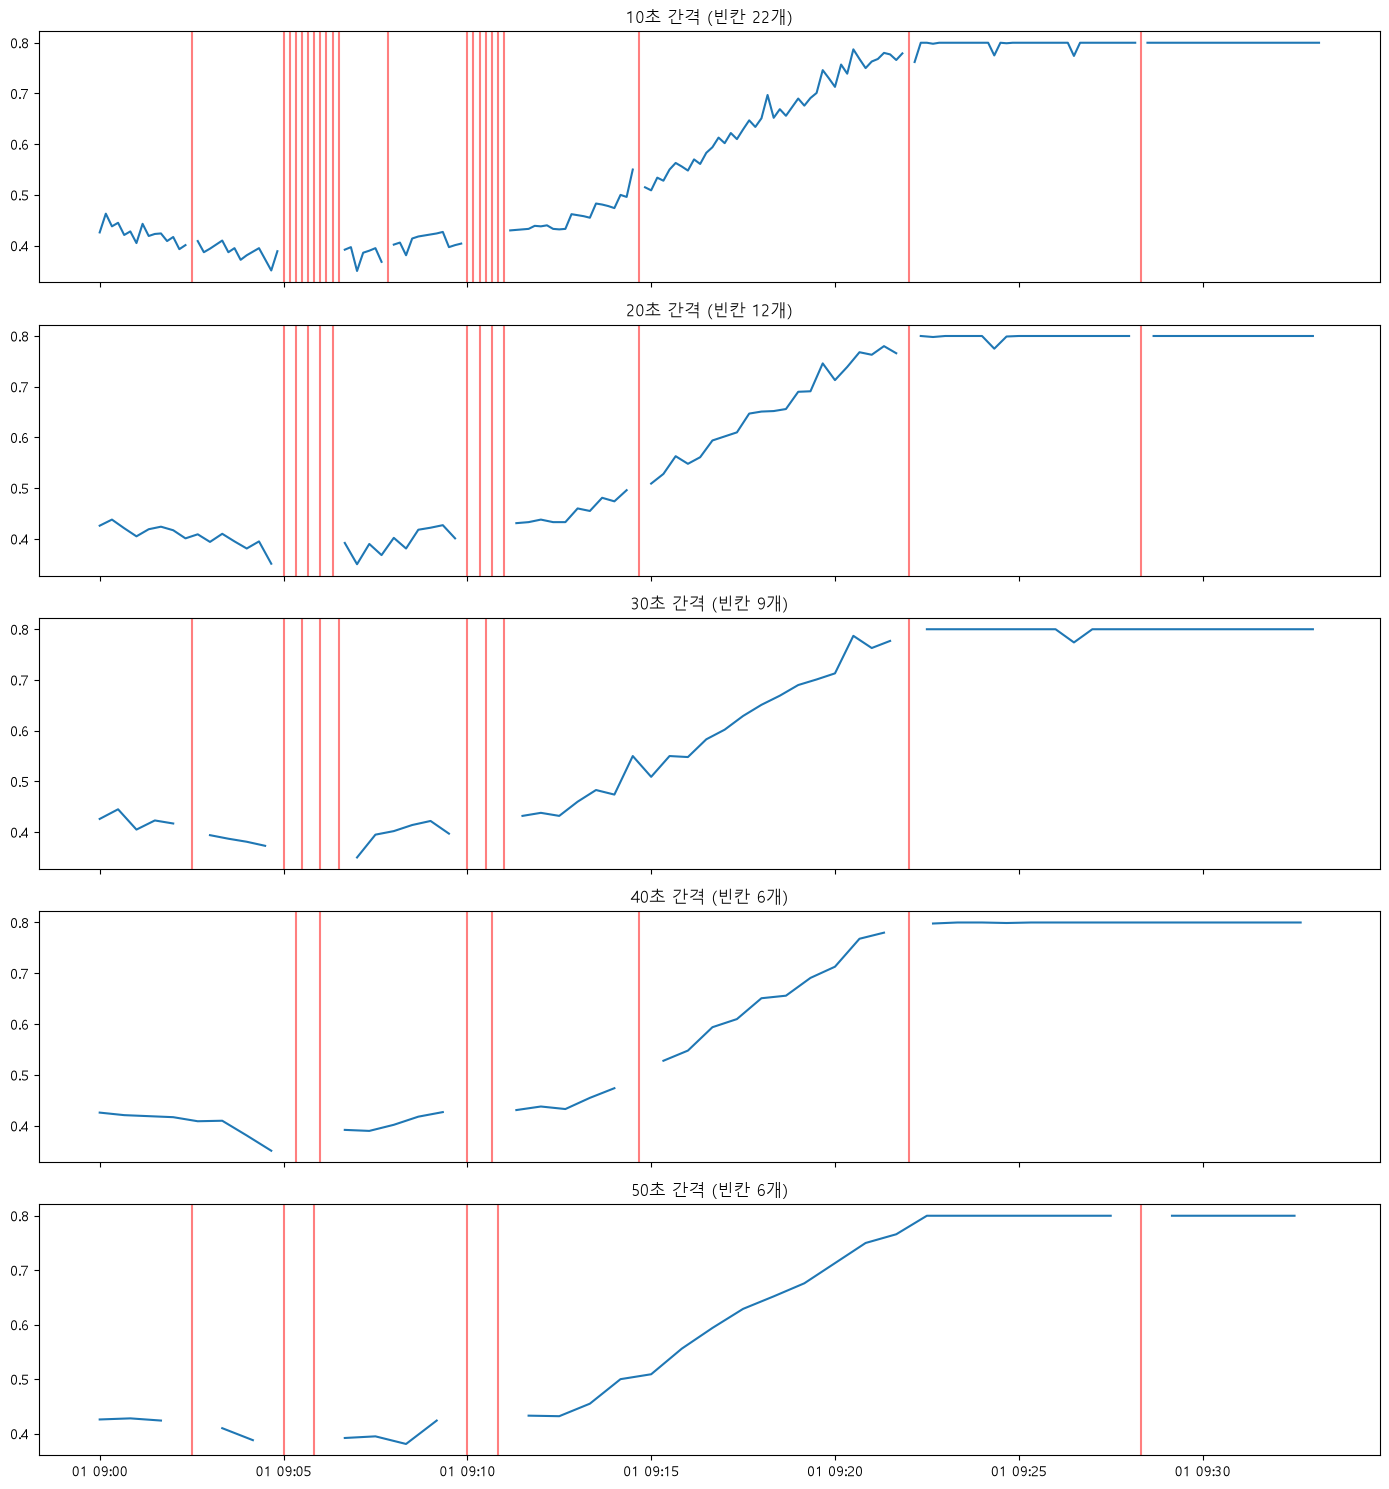

In [ ]:
# 리샘플링 구간을 10초에서 50초까지 설정
sec = [10, 20, 30, 40, 50]

# 가로행을 sec의 요소수 만큼 배정
# x축 공유하도록 설정 : sharex=True
fig, axes = plt.subplots(len(sec), 1, figsize=(14, 15), sharex=True)

# ax와 sec를 zip으로 언패킹
for ax, second in zip(axes, sec):
    a = df[['제어출력','소입로온도']].asfreq(f'{second}s') # 10,20,30,40,50초 구간에 대해 다른값으로 보정하지 않고 해당 간격에 있을 때 그 값을 추출
    nan_time = a.index[a['제어출력'].isna()] # 각 구간에 대해 빈칸이 있는 인덱스들을 뽑아서 nan_time에 저장

    ax.plot(a['제어출력'])
    for t in nan_time:
        ax.axvline(t, color='red', alpha=0.5) # 빈칸의 위치를 수직선으로 반복 표시
        ax.set_title(f'{second}초 간격 (빈칸 {len(nan_time)}개)')

plt.tight_layout()
plt.show()